<a href="https://colab.research.google.com/github/2112rishu/electricity-bill-predictor/blob/main/Electricity_Bill_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os
import requests
from io import BytesIO
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

print("Libraries imported successfully!")


Libraries imported successfully!


In [23]:

url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

print("Downloading dataset...")
response = requests.get(url, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as z:
    txt_file = next(
        name for name in z.namelist()
        if name.endswith("household_power_consumption.txt")
    )
    with z.open(txt_file) as file:
        df = pd.read_csv(
            file,
            sep=";",
            na_values=["?"],
            low_memory=False
        )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())


Dataset loaded successfully!
Dataset shape: (2075259, 9)
Column names: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [24]:

# Remove accidental spaces in column names
df.columns = df.columns.str.strip()

# Convert date and time into one datetime column
date_text = df["Date"].astype(str).str.strip()
time_text = df["Time"].astype(str).str.strip()

if date_text.iloc[0].find("-") != -1:
    date_format = "%Y-%m-%d %H:%M:%S"
else:
    date_format = "%d/%m/%Y %H:%M:%S"

df["datetime"] = pd.to_datetime(
    date_text + " " + time_text,
    format=date_format,
    errors="coerce"
)

# Convert electricity measurements to numeric values
df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"], errors="coerce"
)

# Remove rows with invalid dates or missing power readings
df = df.dropna(subset=["datetime", "Global_active_power"]).copy()

# Sort records by date and time
df = df.sort_values("datetime").reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Missing datetime values:", df["datetime"].isna().sum())
print("Missing active power values:", df["Global_active_power"].isna().sum())

display(df[["Date", "Time", "datetime", "Global_active_power"]].head())


Cleaned dataset shape: (2049280, 10)
Missing datetime values: 0
Missing active power values: 0


,Date,Time,datetime,Global_active_power
0,16/12/2006,17:24:00,2006-12-16 17:24:00,4.216
1,16/12/2006,17:25:00,2006-12-16 17:25:00,5.360
2,16/12/2006,17:26:00,2006-12-16 17:26:00,5.374
3,16/12/2006,17:27:00,2006-12-16 17:27:00,5.388
4,16/12/2006,17:28:00,2006-12-16 17:28:00,3.666


In [25]:

df = df.set_index("datetime")

daily = (
    df["Global_active_power"]
    .resample("D")
    .sum(min_count=1)
    .div(60)
    .to_frame(name="daily_kwh")
)

# Keep a continuous daily calendar
full_dates = pd.date_range(
    start=daily.index.min().normalize(),
    end=daily.index.max().normalize(),
    freq="D"
)
daily = daily.reindex(full_dates)
daily.index.name = "date"

print("Daily dataset shape:", daily.shape)
print("Missing daily consumption values:", daily["daily_kwh"].isna().sum())
display(daily.head())


Daily dataset shape: (1442, 1)
Missing daily consumption values: 9


,daily_kwh
date,
2006-12-16,20.152933
2006-12-17,56.507667
2006-12-18,36.730433
2006-12-19,27.769900
2006-12-20,37.095800


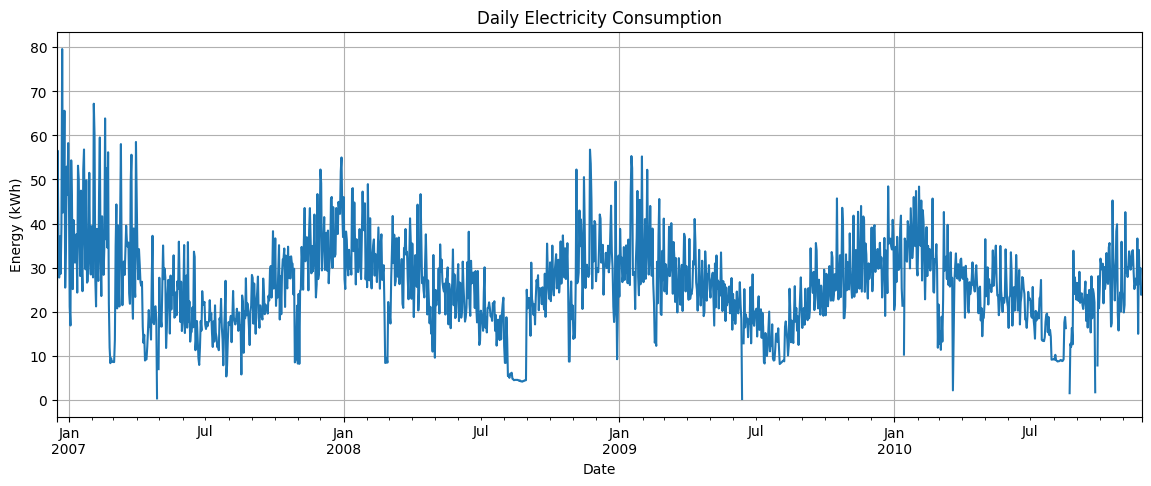

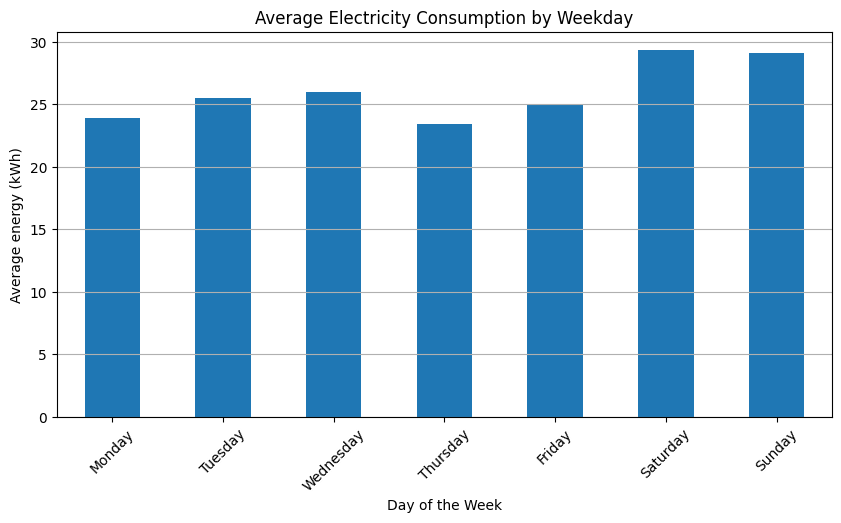

Daily consumption statistics:


,daily_kwh
count,1433.000000
mean,26.017968
std,10.113661
min,0.236967
25%,19.428333
50%,25.710833
75%,31.560133
max,79.556433


In [26]:

# Daily electricity consumption over time
daily["daily_kwh"].plot(figsize=(14, 5), title="Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.grid(True)
plt.show()

# Average consumption for each weekday
weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_average = daily.groupby(daily.index.dayofweek)["daily_kwh"].mean()
weekday_average.index = weekday_names

weekday_average.plot(kind="bar", figsize=(10, 5),
                     title="Average Electricity Consumption by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Average energy (kWh)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

print("Daily consumption statistics:")
display(daily["daily_kwh"].describe())


In [27]:

model_data = daily.copy()

model_data["previous_day_kwh"] = model_data["daily_kwh"].shift(1)
model_data["day_of_week"] = model_data.index.dayofweek
model_data["month"] = model_data.index.month

# Remove rows without a target or previous-day reading
model_data = model_data.dropna().copy()

features = ["previous_day_kwh", "day_of_week", "month"]
target = "daily_kwh"

X = model_data[features]
y = model_data[target]

print("Model dataset shape:", model_data.shape)
display(model_data.head())


Model dataset shape: (1427, 4)


,daily_kwh,previous_day_kwh,day_of_week,month
date,,,,
2006-12-17,56.507667,20.152933,6,12
2006-12-18,36.730433,56.507667,0,12
2006-12-19,27.769900,36.730433,1,12
2006-12-20,37.095800,27.769900,2,12
2006-12-21,28.610400,37.095800,3,12


In [28]:

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training period:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Testing period:", X_test.index.min().date(), "to", X_test.index.max().date())


Training records: 1141
Testing records: 286
Training period: 2006-12-17 to 2010-02-05
Testing period: 2010-02-06 to 2010-11-26


In [29]:

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

print("Model: Linear Regression")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"Mean Absolute Error (MAE): {mae:.3f} kWh")


Model: Linear Regression
Training records: 1141
Testing records: 286
Mean Absolute Error (MAE): 4.931 kWh


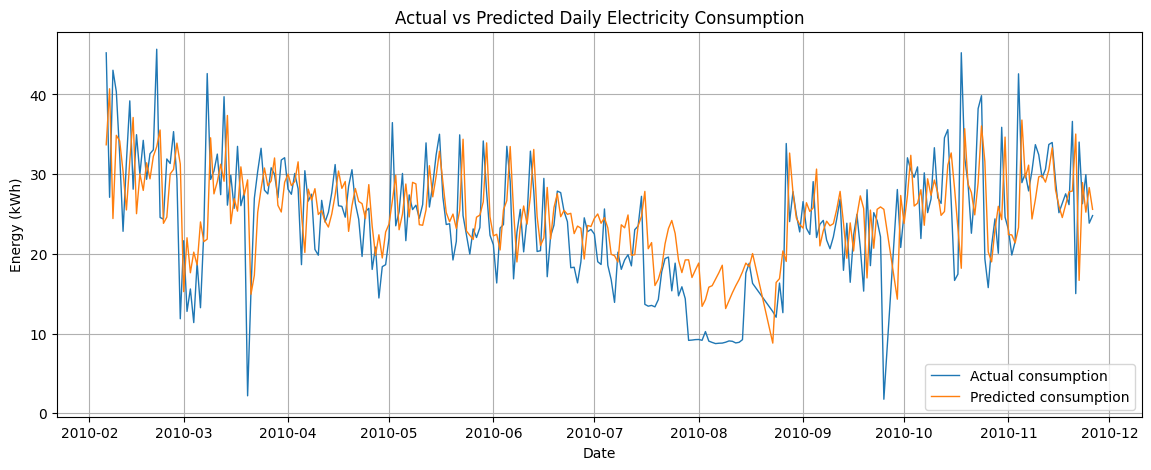

In [30]:

plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual consumption",
    linewidth=1
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted consumption",
    linewidth=1
)

plt.title("Actual vs Predicted Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.grid(True)
plt.show()


In [31]:

# Find the latest date with recorded daily consumption
latest_date = daily["daily_kwh"].last_valid_index()
latest_kwh = daily.loc[latest_date, "daily_kwh"]

# Predict the following calendar day
next_date = latest_date + pd.Timedelta(days=1)

next_day_features = pd.DataFrame(
    [[latest_kwh, next_date.dayofweek, next_date.month]],
    columns=features
)

next_day_prediction = model.predict(next_day_features)[0]

# Consumption cannot be negative
next_day_prediction = max(0, next_day_prediction)

# Illustrative monthly cost estimate
tariff_per_kwh = 8
estimated_monthly_kwh = next_day_prediction * 30
estimated_monthly_cost = estimated_monthly_kwh * tariff_per_kwh

print("PROJECT: Electricity Bill Predictor")
print("-----------------------------------")
print("Model: Linear Regression")
print("Latest historical date:", latest_date.date())
print(f"Latest historical daily usage: {latest_kwh:.2f} kWh")
print("Forecast date:", next_date.date())
print(f"Predicted next-day usage: {next_day_prediction:.2f} kWh")
print(f"Assumed tariff: ₹{tariff_per_kwh:.2f}/kWh")
print(f"Estimated 30-day energy cost: ₹{estimated_monthly_cost:.2f}")
print(f"Test MAE: {mae:.3f} kWh")


PROJECT: Electricity Bill Predictor
-----------------------------------
Model: Linear Regression
Latest historical date: 2010-11-26
Latest historical daily usage: 24.80 kWh
Forecast date: 2010-11-27
Predicted next-day usage: 27.06 kWh
Assumed tariff: ₹8.00/kWh
Estimated 30-day energy cost: ₹6494.80
Test MAE: 4.931 kWh


In [32]:

daily.to_csv("daily_electricity_consumption.csv")

print("Saved: daily_electricity_consumption.csv")

# Download the processed CSV to your computer
from google.colab import files
files.download("daily_electricity_consumption.csv")


Saved: daily_electricity_consumption.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>